# Лабораторная 2. Полиномиальная регрессия. Регуляризация. Кросс-валидация

**Задание 3.** Реализуйте программно восстановление функциональной зависимости
методом наименьших квадратов с помощью полиномиальной регрессии. Для этого

а) используйте значения параметра $M \in \{0, 1, \ldots, 15\}$;

б) генерируйте выборку двумя способами: в первом случае моделируйте ошибку
измерения как равномерно распределённую случайную величину, во втором - как
нормально распределённую случайную величину;

в) генерируйте значения $x$ из заданного интервала случайно в соответствии с
равномерным распределением;

г) в качестве распознаваемых функциональных зависимостей используйте следующие:
$y = \cos x$, $y = 5x^3 + x^2 + 5$, $y = x \sin x$, $x \in [0, 2\pi]$.

**Задание 4.** Докажите, что при ЛАССО-регуляризации линии уровня функции ошибки
и нормы вектора параметров модели (коэффициентов полинома) с вероятностью 1
пересекаются в вершинах гиперкуба, являющегося сферой в норме $L_1$ с центром в
начале координат. Чем определяется центр окружностей линий уровня функции ошибки
без учёта регуляризационного слагаемого?

**Задание 5.** При условиях, сформулированных в задаче 3, реализуйте программно
регуляризацию для полиномиальной регрессии и покажите, что переобучение может быть
устранено при некоторых значениях $M$ и $\lambda$. Найдите эти значения для
выбранных функций и некоторых выборок, полученных для этих функций.

**Задание 6.** Реализуйте программно кросс-валидацию для полиномиальной регрессии с
регуляризацией. Определите наилучшую пару $(M, \lambda)$ для восстановления
функциональных зависимостей из задания 4.

## 1. Теория

### Данные

Выборка $\{(x_k, y_k)\}_{k=1}^{N}$ генерируется как $y_k = f(x_k) + \varepsilon_k$:
значения $x_k$ равномерно распределены на $[0, 2\pi]$, $f$ - одна из функций
$\cos x$, $5x^3 + x^2 + 5$, $x \sin x$. Ошибка измерения равномерная,
$\varepsilon \sim \mathrm{U}[-\varepsilon_0, \varepsilon_0]$, или нормальная,
$\varepsilon \sim \mathrm{N}(0, \sigma^2)$ с $\sigma = \varepsilon_0 / \sqrt3$, чтобы
дисперсии совпадали. Амплитуда $\varepsilon_0$ равна $15\%$ размаха функции на
отрезке. Обучающая выборка 25 точек, тестовая 500.

### Метод наименьших квадратов

Зависимость ищется в виде многочлена $\tilde f(x, w) = \sum_{j=0}^{M} w_j x^j$,
минимизирующего функцию ошибки

$$E(w) = \frac12 \sum_{k=1}^{N}\bigl(y_k - \tilde f(x_k, w)\bigr)^2 .$$

Условия $\partial E / \partial w_i = 0$ дают систему нормальных уравнений

$$\sum_{j=0}^{M} a_{ij} w_j = b_i, \qquad
a_{ij} = \sum_{k} x_k^{\,i+j}, \qquad b_i = \sum_{k} x_k^{\,i} y_k,
\qquad i = 0, \ldots, M,$$

кратко $Aw = b$. Решение единственно, если среди $x_k$ не меньше $M + 1$
различных значений.

### Регуляризация

Тихоновская (гребневая) регуляризация добавляет к функции ошибки штраф за
величину коэффициентов, свободный член $w_0$ не штрафуется:

$$E_\lambda(w) = \frac12\sum_{k=1}^{N}\bigl(y_k - \tilde f(x_k, w)\bigr)^2
             + \frac{\lambda}{2}\sum_{j=1}^{M} w_j^2 .$$

Производная штрафа по $w_i$ равна $\lambda w_i$ при $i \ge 1$ и нулю при $i = 0$,
поэтому условия $\partial E_\lambda / \partial w_i = 0$ отличаются от нормальных
уравнений только слагаемым $\lambda w_i$:

$$\sum_{j=0}^{M} a_{ij} w_j + \lambda w_i = b_i \ \ (i \ge 1), \qquad
\sum_{j=0}^{M} a_{0j} w_j = b_0,$$

кратко

$$(A + \lambda I_0)\,w = b, \qquad I_0 = \mathrm{diag}(0, 1, \ldots, 1),$$

то есть $\lambda$ прибавляется ко всем диагональным элементам $A$, кроме первого.

### Кросс-валидация

Выборка случайно разбивается на $F$ частей. Модель $F$ раз обучается на $F - 1$
частях и оценивается на оставшейся, ошибки усредняются. Наилучшей считается пара
$(M, \lambda)$ с наименьшей средней ошибкой.

### Масштабирование аргумента

Многочлен строится от $t = x / \pi - 1 \in [-1, 1]$, а не от $x$. Причина в
точности вычислений: при $x$ до $2\pi$ и $M = 15$ элемент $a_{00} = N$, а
$a_{MM} = \sum_k x_k^{30}$ порядка $(2\pi)^{30} \approx 10^{24}$. Компьютер хранит
около 16 значащих цифр, и при таком разбросе элементов система решается с большой
погрешностью. При $|t| \le 1$ все степени $t^j$ по модулю не больше 1, и все
$a_{ij}$ не больше $N$. Модель от этого не меняется: подстановка $t = x/\pi - 1$
переводит многочлен степени $M$ от $t$ в многочлен той же степени от $x$, поэтому
ищется та же зависимость. Коэффициенты $w$ и штраф относятся к многочлену от $t$.

### Что перебирается

| Гиперпараметр | Значения |
|---|---|
| степень $M$ | 0, 1, ..., 15 |
| $\lambda$ | 0 и 25 значений от $10^{-10}$ до $10^{2}$, равномерно по $\log_{10}\lambda$ |
| ошибка измерения | равномерная, нормальная |
| число частей $F$ | 5 |

### Мера ошибки

$$\mathrm{RMSE} = \sqrt{\frac1n \sum_{k=1}^{n}\bigl(\tilde f(x_k, w) - y_k\bigr)^2}.$$

## 2. Генерация выборки

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams['figure.dpi'] = 110

A_INT, B_INT = 0.0, 2 * np.pi
FUNCS = {
    'cos x': lambda x: np.cos(x),
    '5x^3 + x^2 + 5': lambda x: 5 * x ** 3 + x ** 2 + 5,
    'x sin x': lambda x: x * np.sin(x),
}
NOISES = ['равномерный', 'нормальный']
N_TRAIN, N_TEST = 25, 500
SEED = 20260905

In [2]:
def make_sample(f, n, noise, eps, rng):
    """n точек: x равномерно на [0, 2pi], y = f(x) + ошибка."""
    x = rng.uniform(A_INT, B_INT, n)
    if noise == 'равномерный':
        e = rng.uniform(-eps, eps, n)
    else:
        e = rng.normal(0.0, eps / np.sqrt(3), n)
    return x, f(x) + e


grid = np.linspace(A_INT, B_INT, 1000)
NOISE_SCALE = {}
rows = []
for name, f in FUNCS.items():
    span = f(grid).max() - f(grid).min()
    NOISE_SCALE[name] = 0.15 * span
    rows.append({'функция': name, 'размах': span, 'амплитуда ошибки': NOISE_SCALE[name]})
print(pd.DataFrame(rows).round(3).to_string(index=False))


def train_test(name, noise):
    """Обучающая и тестовая выборки для функции name и вида ошибки noise."""
    rng = np.random.default_rng(SEED)
    x_tr, y_tr = make_sample(FUNCS[name], N_TRAIN, noise, NOISE_SCALE[name], rng)
    x_te, y_te = make_sample(FUNCS[name], N_TEST, noise, NOISE_SCALE[name], rng)
    return x_tr, y_tr, x_te, y_te

       функция   размах  амплитуда ошибки
         cos x    2.000             0.300
5x^3 + x^2 + 5 1279.729           191.959
       x sin x    6.634             0.995


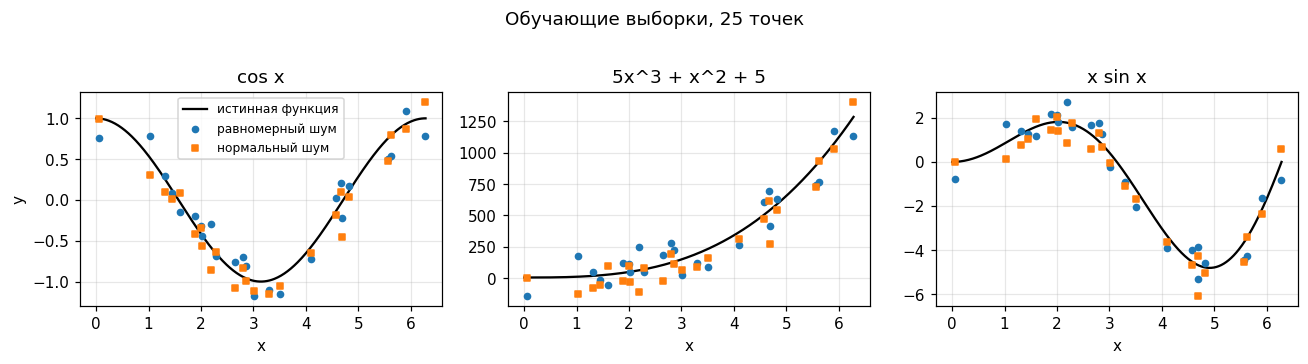

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
grid = np.linspace(A_INT, B_INT, 400)
for ax, name in zip(axes, FUNCS):
    ax.plot(grid, FUNCS[name](grid), color='black', label='истинная функция')
    for noise, marker in zip(NOISES, ['o', 's']):
        x_tr, y_tr, _, _ = train_test(name, noise)
        ax.scatter(x_tr, y_tr, s=16, marker=marker, zorder=3, label=f'{noise} шум')
    ax.set_title(name)
    ax.set_xlabel('x')
    ax.grid(alpha=0.3)
axes[0].set_ylabel('y')
axes[0].legend(fontsize=8)
fig.suptitle('Обучающие выборки, 25 точек', y=1.02)
plt.tight_layout()
plt.show()

## 3. Реализация полиномиальной регрессии

In [4]:
def scale(x):
    """Перенос отрезка [0, 2pi] в [-1, 1]: t = x / pi - 1."""
    return x / np.pi - 1.0


def normal_system(t, y, M):
    """Система Aw = b: a_ij = сумма t^(i+j), b_i = сумма t^i y."""
    A = np.empty((M + 1, M + 1))
    b = np.empty(M + 1)
    for i in range(M + 1):
        b[i] = np.sum(t ** i * y)
        for j in range(M + 1):
            A[i, j] = np.sum(t ** (i + j))
    return A, b


def fit(x, y, M, lam=0.0):
    """Коэффициенты многочлена степени M из системы (A + lambda I_0) w = b."""
    A, b = normal_system(scale(x), y, M)
    for j in range(1, M + 1):
        A[j, j] += lam  # w_0 не штрафуется
    return np.linalg.solve(A, b)


def predict(w, x):
    """Значения многочлена с коэффициентами w в точках x."""
    t = scale(x)
    return sum(w[j] * t ** j for j in range(len(w)))


def rmse(w, x, y):
    return float(np.sqrt(np.mean((predict(w, x) - y) ** 2)))

## 4. Задание 3: перебор степени многочлена

In [5]:
MS = list(range(16))

rows = []
for name in FUNCS:
    for noise in NOISES:
        x_tr, y_tr, x_te, y_te = train_test(name, noise)
        for M in MS:
            w = fit(x_tr, y_tr, M)
            rows.append(dict(func=name, noise=noise, M=M,
                             train=rmse(w, x_tr, y_tr), test=rmse(w, x_te, y_te)))
plain = pd.DataFrame(rows)

for column, title in [('train', 'обучающей'), ('test', 'тестовой')]:
    print(f'RMSE на {title} выборке:')
    print(plain.pivot_table(index='M', columns=['func', 'noise'], values=column).round(4).to_string())
    print()

RMSE на обучающей выборке:
func  5x^3 + x^2 + 5                  cos x                x sin x            
noise     нормальный равномерный нормальный равномерный нормальный равномерный
M                                                                             
0           391.5256    351.9618     0.6927      0.6437     2.5233      2.6164
1           179.5582    153.8346     0.6668      0.6286     1.7872      1.7512
2            96.1150    114.2537     0.2151      0.2950     1.7863      1.7403
3            86.0637    105.1019     0.2142      0.2942     0.8851      0.7673
4            82.0246    102.1584     0.1348      0.1616     0.4634      0.5896
5            81.8697    102.1576     0.1338      0.1614     0.4084      0.5353
6            78.6484    102.0842     0.1229      0.1597     0.4070      0.5314
7            78.2513     96.0219     0.1223      0.1504     0.4059      0.4959
8            78.0598     74.1965     0.1220      0.1159     0.4047      0.3848
9            77.7126     

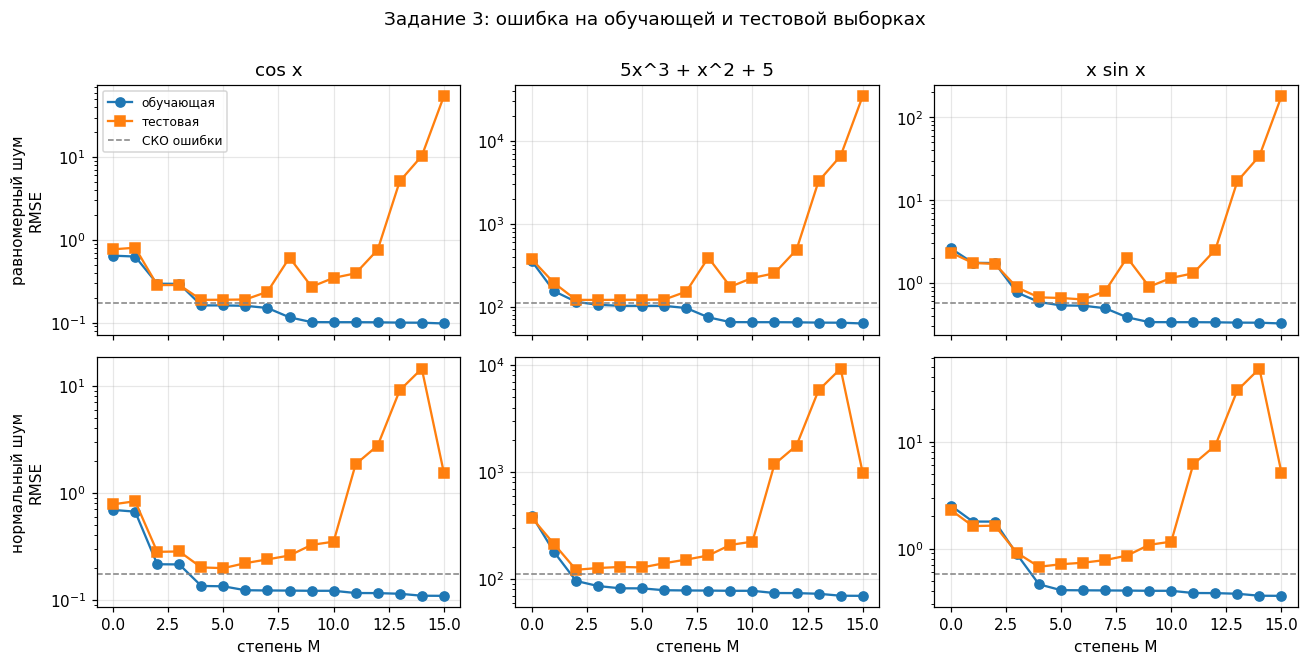

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6), sharex=True)
for col, name in enumerate(FUNCS):
    for row, noise in enumerate(NOISES):
        ax = axes[row, col]
        s = plain[(plain.func == name) & (plain.noise == noise)]
        ax.semilogy(s.M, s.train, marker='o', label='обучающая')
        ax.semilogy(s.M, s.test, marker='s', label='тестовая')
        ax.axhline(NOISE_SCALE[name] / np.sqrt(3), color='gray', ls='--', lw=1,
                   label='СКО ошибки')
        ax.grid(alpha=0.3)
        if row == 0:
            ax.set_title(name)
        if row == 1:
            ax.set_xlabel('степень M')
        if col == 0:
            ax.set_ylabel(f'{noise} шум\nRMSE')
axes[0, 0].legend(fontsize=8)
fig.suptitle('Задание 3: ошибка на обучающей и тестовой выборках', y=1.0)
plt.tight_layout()
plt.show()

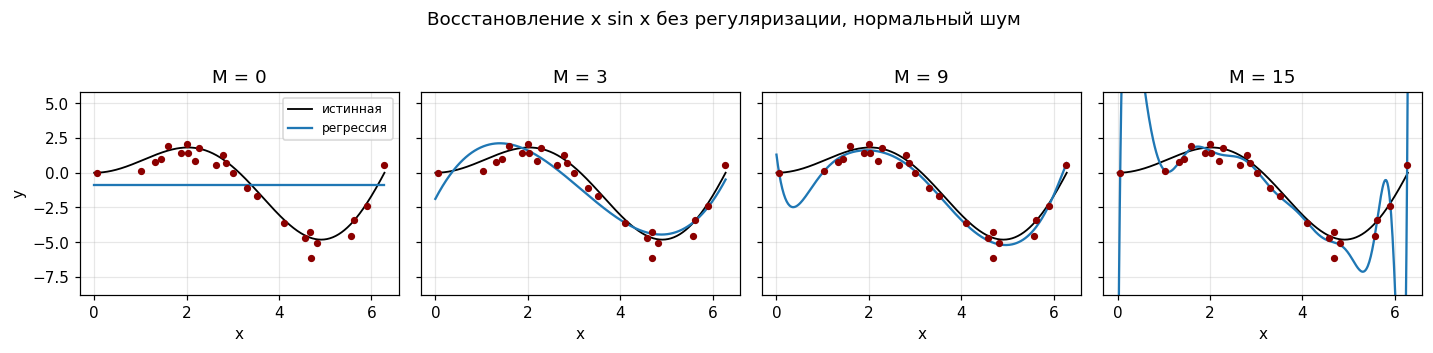

In [7]:
name = 'x sin x'
x_tr, y_tr, _, _ = train_test(name, 'нормальный')
grid = np.linspace(A_INT, B_INT, 400)
fig, axes = plt.subplots(1, 4, figsize=(13, 3.1), sharey=True)
for ax, M in zip(axes, [0, 3, 9, 15]):
    w = fit(x_tr, y_tr, M)
    ax.plot(grid, FUNCS[name](grid), color='black', lw=1.2, label='истинная')
    ax.plot(grid, predict(w, grid), color='tab:blue', label='регрессия')
    ax.scatter(x_tr, y_tr, color='darkred', s=14, zorder=3)
    ax.set_ylim(FUNCS[name](grid).min() - 4, FUNCS[name](grid).max() + 4)
    ax.set_title(f'M = {M}')
    ax.set_xlabel('x')
    ax.grid(alpha=0.3)
axes[0].set_ylabel('y')
axes[0].legend(fontsize=8)
fig.suptitle('Восстановление x sin x без регуляризации, нормальный шум', y=1.02)
plt.tight_layout()
plt.show()

## 5. Задание 4: ЛАССО-регуляризация

При ЛАССО-регуляризации штраф берётся по норме $L_1$, свободный член не
штрафуется:

$$E_\lambda(w) = E(w) + \frac{\lambda}{2}\sum_{j=1}^{M}\lvert w_j\rvert .$$

**Используемые факты.**

1. Если случайная величина $\varepsilon$ имеет плотность распределения и не
   зависит от величины $\zeta$, то $P(\varepsilon = \zeta) = 0$: при каждом
   значении $\zeta$ величина $\varepsilon$ принимает это значение с вероятностью 0.
2. Функция распределения $F(t) = P(\xi \le t)$ непрерывна справа: $F(t) \to F(0)$
   при $t \to 0$, $t > 0$.
3. Теорема Пифагора: если $p$ - основание перпендикуляра из точки $z$ на прямую,
   то для любой точки $q$ этой прямой
   $\lVert z - q\rVert^2 = \lVert z - p\rVert^2 + \lVert p - q\rVert^2$.

**Минимум со штрафом - это минимум на шаре.** Пусть $w^*$ - точка минимума
$E_\lambda$ и $\eta = \sum_{j \ge 1}\lvert w^*_j\rvert$. Для любого $w$ из шара
$\sum_{j \ge 1}\lvert w_j\rvert \le \eta$

$$E(w) = E_\lambda(w) - \frac{\lambda}{2}\sum_{j \ge 1}\lvert w_j\rvert
\ge E_\lambda(w^*) - \frac{\lambda}{2}\eta = E(w^*),$$

так как $E_\lambda(w) \ge E_\lambda(w^*)$ и $\sum_{j \ge 1}\lvert w_j\rvert \le \eta$.
Значит, $w^*$ - точка минимума $E$ на шаре радиуса $\eta$ в норме $L_1$, и линия
уровня $E$, проходящая через $w^*$, касается сферы
$\sum_{j \ge 1}\lvert w_j\rvert = \eta$. При двух координатах эта сфера - квадрат с
вершинами $(\pm\eta, 0)$, $(0, \pm\eta)$, при $n$ координатах - многогранник с
вершинами $\pm\eta e_j$, где у $e_j$ на $j$-м месте единица, на остальных нули (в
условии он назван гиперкубом). В вершине все координаты, кроме одной, равны нулю.
Радиус стремится к нулю с ростом $\lambda$: так как $E \ge 0$,

$$\frac{\lambda}{2}\eta \le E(w^*) + \frac{\lambda}{2}\eta = E_\lambda(w^*)
\le E_\lambda(0) = E(0), \qquad \eta \le \frac{2E(0)}{\lambda}.$$

Поэтому дальше рассматривается минимум $E$ на шаре заданного радиуса $\eta$, и
сильной регуляризации отвечает малое $\eta$.

**Центр линий уровня.** Пусть $\hat w$ - решение системы $A\hat w = b$, то есть
точка минимума $E$ без регуляризации, и $d_k = y_k - \tilde f(x_k, \hat w)$. Модель
линейна по $w$, поэтому при $w = \hat w + h$ имеем
$y_k - \tilde f(x_k, w) = d_k - \tilde f(x_k, h)$ и

$$E(w) = \frac12\sum_k \bigl(d_k - \tilde f(x_k, h)\bigr)^2
= E(\hat w) - \sum_i h_i \sum_k x_k^{\,i} d_k + \frac12\sum_k \tilde f(x_k, h)^2 .$$

Средняя сумма равна нулю: $\sum_k x_k^{\,i} d_k = b_i - \sum_j a_{ij}\hat w_j = 0$ -
это $i$-е уравнение системы. В последней сумме
$\tilde f(x_k, h)^2 = \sum_{i,j} h_i h_j x_k^{\,i} x_k^{\,j}$, и суммирование по $k$
даёт $a_{ij}$. Поэтому

$$E(w) = E(\hat w) + \frac12\sum_{i,j} a_{ij}\,(w_i - \hat w_i)(w_j - \hat w_j).$$

Линии уровня $E(w) = c$ - эллипсы с центром $\hat w$, при $A = aI$ - окружности
$\lVert w - \hat w\rVert^2 = 2\bigl(c - E(\hat w)\bigr)/a$. Ответ на второй вопрос
задания: центр - это решение $\hat w$ системы $A\hat w = b$, то есть решение
методом наименьших квадратов без регуляризации; он определяется выборкой
$(x_k, y_k)$. Та же выкладка верна для любой модели
$\tilde f(x, w) = \sum_i w_i\varphi_i(x)$, линейной по параметрам, с заменой
$x_k^{\,i}$ на $\varphi_i(x_k)$.

**Два коэффициента, окружности.** Пусть
$\tilde f(x, w) = w_1\varphi_1(x) + w_2\varphi_2(x)$, оба коэффициента штрафуются,
точки $x_k$ фиксированы, а случайны только ошибки $\varepsilon_k$. Линии уровня,
как в условии, - окружности: $A = aI$, где
$a_{ij} = \sum_k \varphi_i(x_k)\varphi_j(x_k)$, то есть $a_{11} = a_{22} = a > 0$ и
$a_{12} = 0$. Тогда $E(w) = E(\hat w) + \frac a2\lVert w - \hat w\rVert^2$, и
минимум $E$ на шаре - это ближайшая к $\hat w$ точка шара.

Если $\hat w$ лежит в шаре, это сам $\hat w$. Пусть $\hat w$ вне шара. Замена знака
координаты переводит шар в себя, поэтому можно считать $\hat w = (u, v)$ с
$u, v \ge 0$. Ближайшую точку можно искать в первой четверти: для точки $q$ шара
точка $(\lvert q_1\rvert, \lvert q_2\rvert)$ тоже лежит в шаре и не дальше от
$\hat w$, так как $\bigl\lvert\, \lvert q_1\rvert - u\bigr\rvert \le \lvert q_1 - u\rvert$
(при $q_1 \ge 0$ это равенство, при $q_1 < 0$ справа стоит $u + \lvert q_1\rvert$), и
так же для второй координаты. Кроме того, ближайшая точка лежит на границе шара:
от точки внутри шара можно немного сдвинуться к $\hat w$, оставаясь в шаре. Значит,
ближайшая точка лежит на стороне $w_1 + w_2 = \eta$, $w_1, w_2 \ge 0$.

Вектор $(1, 1)$ перпендикулярен этой стороне, поэтому основание перпендикуляра из
$\hat w$ на прямую $w_1 + w_2 = \eta$ равно $p = (u, v) - s\,(1, 1)$, где $s$
находится из $p_1 + p_2 = \eta$: $s = (u + v - \eta)/2$ и

$$p = \Bigl(\frac{u - v + \eta}{2},\ \frac{v - u + \eta}{2}\Bigr).$$

По теореме Пифагора ближе всего к $\hat w$ та точка стороны, которая ближе всего к
$p$. Если $\lvert u - v\rvert < \eta$, обе координаты $p$ положительны, $p$ лежит
внутри стороны, и окружность касается стороны не в вершине. Если $u - v \ge \eta$,
вторая координата $p$ не больше нуля, и ближайшая к $p$ точка стороны - её конец
$(\eta, 0)$, то есть вершина; при $v - u \ge \eta$ так же получается вершина
$(0, \eta)$.

Вернём знаки: $u = \lvert\hat w_1\rvert$, $v = \lvert\hat w_2\rvert$, и обозначим
$\xi = \bigl\lvert\, \lvert\hat w_1\rvert - \lvert\hat w_2\rvert \,\bigr\rvert$. Если
$\hat w$ вне шара, касание происходит не в вершине тогда и только тогда, когда
$\xi < \eta$. Если $\hat w$ в шаре, то
$\xi \le \lvert\hat w_1\rvert + \lvert\hat w_2\rvert \le \eta$. В обоих случаях
минимум $E$ на шаре может лежать не в вершине, только если $\xi \le \eta$.

**Вероятность.** Пусть $F$ - функция распределения $\xi$. Так как $\xi \ge 0$, по
факту 2

$$P(\text{минимум не в вершине}) \le P(\xi \le \eta) = F(\eta) \longrightarrow
F(0) = P(\xi = 0) \quad \text{при } \eta \to 0 .$$

Осталось показать, что $P(\xi = 0) = 0$. Равенство $\xi = 0$ означает
$\hat w_1 = \hat w_2$ или $\hat w_1 = -\hat w_2$. Из $A = aI$ получаем
$\hat w = b/a$, где $b_i = \sum_k \varphi_i(x_k)\,y_k$, поэтому

$$\hat w_1 \mp \hat w_2 = \frac1a\sum_k c_k y_k, \qquad
c_k = \varphi_1(x_k) \mp \varphi_2(x_k).$$

Не все $c_k$ равны нулю: $\sum_k c_k^2 = a_{11} \mp 2a_{12} + a_{22} = 2a > 0$.
Пусть $c_m \ne 0$. Так как $y_m = f(x_m) + \varepsilon_m$, равенство
$\sum_k c_k y_k = 0$ означает $\varepsilon_m = \zeta$, где

$$\zeta = -f(x_m) - \frac{1}{c_m}\sum_{k \ne m} c_k y_k$$

зависит только от остальных ошибок. Ошибка $\varepsilon_m$ имеет плотность и не
зависит от остальных ошибок, поэтому по факту 1 $P(\varepsilon_m = \zeta) = 0$.
Значит, $P(\hat w_1 = \hat w_2) = P(\hat w_1 = -\hat w_2) = 0$ и $P(\xi = 0) = 0$.

Итак, при $\eta \to 0$ вероятность того, что линии уровня функции ошибки касаются
$L_1$-сферы в вершине, стремится к 1, и тогда один из двух коэффициентов решения
равен нулю. При фиксированном $\eta$ касание стороны возможно, если $\xi < \eta$.
$\blacksquare$

**Замечание (общий случай).** При $n$ штрафуемых коэффициентах и $A = aI$ после
смены знаков и перенумерации $\hat w_1 \ge \hat w_2 \ge \dots \ge \hat w_n \ge 0$
ближайшая к $\hat w$ точка многогранника - вершина $\eta e_1$ тогда и только тогда,
когда $\hat w_1 - \hat w_2 \ge \eta$. Равенство
$\lvert\hat w_i\rvert = \lvert\hat w_j\rvert$ при $i \ne j$ имеет вероятность 0 по тем
же причинам, поэтому вероятность касания в вершине так же стремится к 1 при
$\eta \to 0$.

## 6. Задание 5: регуляризация

In [8]:
LAMBDAS = np.concatenate([[0.0], np.logspace(-10, 2, 25)])

rows = []
for name in FUNCS:
    for noise in NOISES:
        x_tr, y_tr, x_te, y_te = train_test(name, noise)
        for M in MS:
            for lam in LAMBDAS:
                w = fit(x_tr, y_tr, M, lam)
                rows.append(dict(func=name, noise=noise, M=M, lam=lam,
                                 train=rmse(w, x_tr, y_tr), test=rmse(w, x_te, y_te)))
reg = pd.DataFrame(rows)

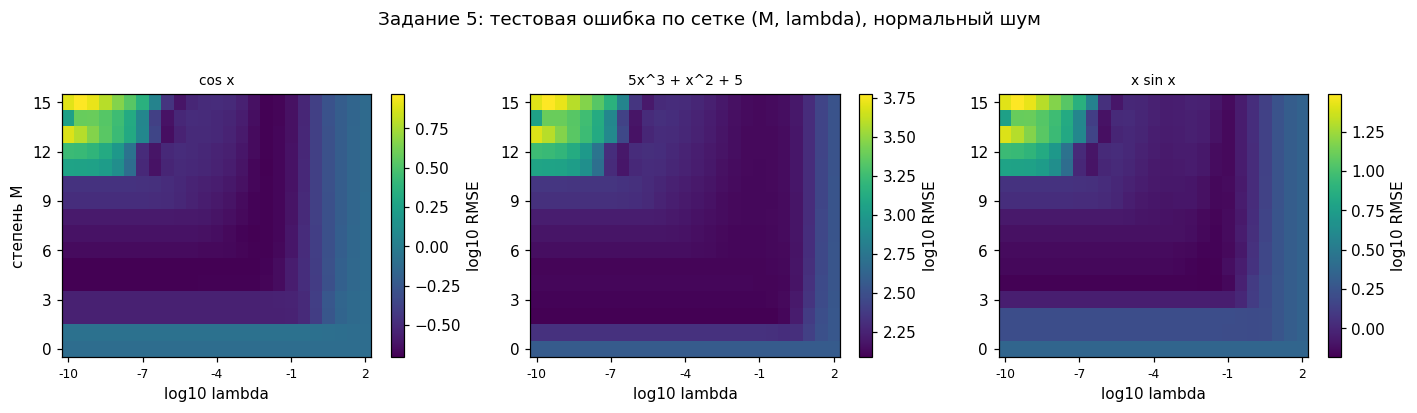

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, name in zip(axes, FUNCS):
    s = reg[(reg.func == name) & (reg.noise == 'нормальный') & (reg.lam > 0)]
    piv = s.pivot_table(index='M', columns='lam', values='test')  # строки - M, столбцы - lambda
    im = ax.imshow(np.log10(piv.values), aspect='auto', origin='lower', cmap='viridis')
    ax.set_title(name, fontsize=9)
    ax.set_xlabel('log10 lambda')
    ax.set_xticks(range(0, len(piv.columns), 6))
    ax.set_xticklabels([f'{np.log10(v):.0f}' for v in piv.columns[::6]], fontsize=8)
    ax.set_yticks(range(0, 16, 3))
    plt.colorbar(im, ax=ax, label='log10 RMSE')
axes[0].set_ylabel('степень M')
fig.suptitle('Задание 5: тестовая ошибка по сетке (M, lambda), нормальный шум', y=1.03)
plt.tight_layout()
plt.show()

In [10]:
def best_row(df, column):
    """Строка таблицы df с наименьшим значением в столбце column."""
    return df.loc[df[column].idxmin()]


rows_15, rows_best = [], []
for name in FUNCS:
    for noise in NOISES:
        g = reg[(reg.func == name) & (reg.noise == noise)]
        g15 = g[g.M == 15]
        b15 = best_row(g15[g15.lam > 0], 'test')
        rows_15.append({'функция': name, 'шум': noise,
                        'тест, lambda = 0': g15[g15.lam == 0].test.iloc[0],
                        'lambda': b15.lam, 'тест': b15.test})
        b0 = best_row(g[g.lam == 0], 'test')
        b = best_row(g[g.lam > 0], 'test')
        rows_best.append({'функция': name, 'шум': noise,
                          'M без рег.': b0.M, 'тест без рег.': b0.test,
                          'M': b.M, 'lambda': b.lam, 'тест': b.test})

print('M = 15: тестовая RMSE без регуляризации и при лучшем lambda')
print(pd.DataFrame(rows_15).to_string(index=False, float_format='{:.4g}'.format))
print('\nЛучшие M и lambda по тестовой RMSE')
print(pd.DataFrame(rows_best).to_string(index=False, float_format='{:.4g}'.format))

M = 15: тестовая RMSE без регуляризации и при лучшем lambda
       функция         шум  тест, lambda = 0   lambda   тест
         cos x равномерный             54.16 0.003162  0.215
         cos x  нормальный             1.545     0.01 0.2021
5x^3 + x^2 + 5 равномерный         3.466e+04      0.1  121.4
5x^3 + x^2 + 5  нормальный             988.7      0.1  134.6
       x sin x равномерный             179.7 0.003162 0.6395
       x sin x  нормальный             5.126      0.1 0.7325

Лучшие M и lambda по тестовой RMSE
       функция         шум  M без рег.  тест без рег.  M   lambda   тест
         cos x равномерный           4         0.1886  4 0.003162  0.188
         cos x  нормальный           5         0.1978  5    1e-10 0.1978
5x^3 + x^2 + 5 равномерный           3          120.4  8 0.003162  120.3
5x^3 + x^2 + 5  нормальный           2          122.2  2      0.1  121.8
       x sin x равномерный           6          0.632  8    0.001  0.621
       x sin x  нормальный           4 

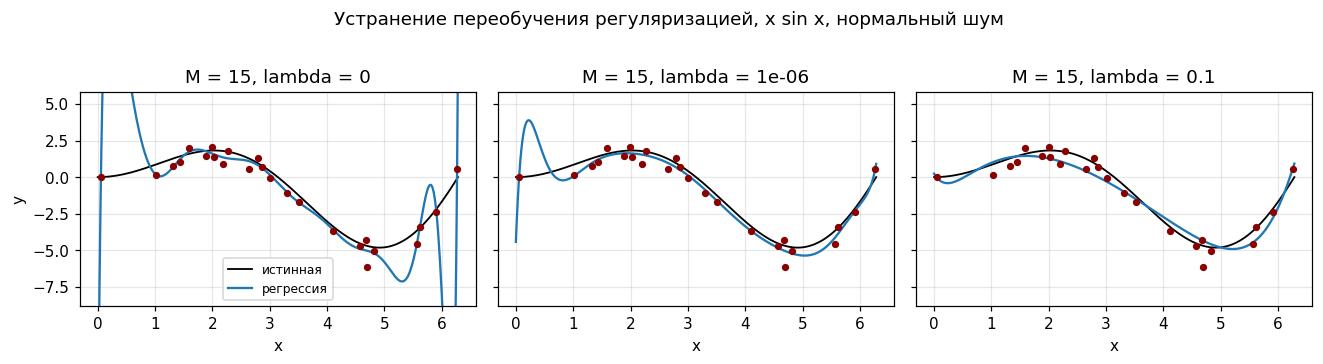

In [11]:
name = 'x sin x'
x_tr, y_tr, _, _ = train_test(name, 'нормальный')
g15 = reg[(reg.func == name) & (reg.noise == 'нормальный') & (reg.M == 15) & (reg.lam > 0)]
lam_best = best_row(g15, 'test').lam
grid = np.linspace(A_INT, B_INT, 400)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
for ax, lam in zip(axes, [0.0, 1e-6, lam_best]):
    w = fit(x_tr, y_tr, 15, lam)
    ax.plot(grid, FUNCS[name](grid), color='black', lw=1.2, label='истинная')
    ax.plot(grid, predict(w, grid), color='tab:blue', label='регрессия')
    ax.scatter(x_tr, y_tr, color='darkred', s=14, zorder=3)
    ax.set_ylim(FUNCS[name](grid).min() - 4, FUNCS[name](grid).max() + 4)
    ax.set_title(f'M = 15, lambda = {lam:.2g}')
    ax.set_xlabel('x')
    ax.grid(alpha=0.3)
axes[0].set_ylabel('y')
axes[0].legend(fontsize=8)
fig.suptitle('Устранение переобучения регуляризацией, x sin x, нормальный шум', y=1.02)
plt.tight_layout()
plt.show()

## 7. Задание 6: кросс-валидация

In [12]:
def cv_error(x, y, M, lam, folds, rng):
    """Средняя RMSE по отложенным частям выборки."""
    idx = rng.permutation(len(x))  # номера точек в случайном порядке
    parts = np.array_split(idx, folds)  # folds частей почти равного размера
    errs = []
    for i in range(folds):
        val = parts[i]
        tr = np.concatenate([parts[j] for j in range(folds) if j != i])
        w = fit(x[tr], y[tr], M, lam)
        errs.append(rmse(w, x[val], y[val]))
    return float(np.mean(errs))

In [13]:
rows = []
for name in FUNCS:
    for noise in NOISES:
        x_tr, y_tr, x_te, y_te = train_test(name, noise)
        for M in MS:
            for lam in LAMBDAS:
                # одно и то же разбиение на части для всех пар (M, lambda)
                cv = cv_error(x_tr, y_tr, M, lam, folds=5, rng=np.random.default_rng(1))
                w = fit(x_tr, y_tr, M, lam)
                rows.append(dict(func=name, noise=noise, M=M, lam=lam,
                                 cv=cv, test=rmse(w, x_te, y_te)))
cvres = pd.DataFrame(rows)
cvres.to_csv('results.csv', index=False)

In [14]:
rows = []
for name in FUNCS:
    for noise in NOISES:
        b = best_row(cvres[(cvres.func == name) & (cvres.noise == noise)], 'cv')
        rows.append({'функция': name, 'шум': noise, 'M': b.M, 'lambda': b.lam,
                     'RMSE CV': b.cv, 'RMSE тест': b.test})
best_cv = pd.DataFrame(rows)
print('Наилучшие пары (M, lambda) по кросс-валидации')
print(best_cv.to_string(index=False, float_format='{:.4g}'.format))

Наилучшие пары (M, lambda) по кросс-валидации
       функция         шум  M    lambda  RMSE CV  RMSE тест
         cos x равномерный  5 0.0003162   0.2093     0.1889
         cos x  нормальный  4      0.01   0.1805     0.2074
5x^3 + x^2 + 5 равномерный  3    0.3162    129.8      125.7
5x^3 + x^2 + 5  нормальный  4       0.1    102.5      129.1
       x sin x равномерный  4   0.03162   0.7548     0.6906
       x sin x  нормальный  5         0    0.683     0.7134


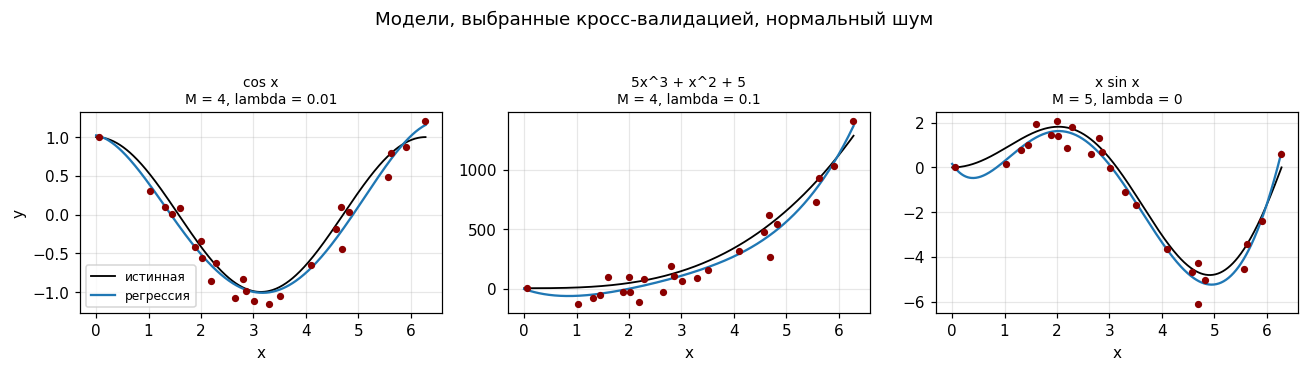

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
grid = np.linspace(A_INT, B_INT, 400)
for ax, name in zip(axes, FUNCS):
    row = best_cv[(best_cv['функция'] == name) & (best_cv['шум'] == 'нормальный')].iloc[0]
    x_tr, y_tr, _, _ = train_test(name, 'нормальный')
    w = fit(x_tr, y_tr, int(row['M']), float(row['lambda']))
    ax.plot(grid, FUNCS[name](grid), color='black', lw=1.2, label='истинная')
    ax.plot(grid, predict(w, grid), color='tab:blue', label='регрессия')
    ax.scatter(x_tr, y_tr, color='darkred', s=14, zorder=3)
    ax.set_title(f"{name}\nM = {int(row['M'])}, lambda = {row['lambda']:.2g}", fontsize=9)
    ax.set_xlabel('x')
    ax.grid(alpha=0.3)
axes[0].set_ylabel('y')
axes[0].legend(fontsize=8)
fig.suptitle('Модели, выбранные кросс-валидацией, нормальный шум', y=1.04)
plt.tight_layout()
plt.show()